# Семинар 2

**Данные:** PBMC 3k (периферическая кровь человека, 10x Genomics)

В первом семинаре мы получили матрицу экспрессии, провели QC, нормализацию, выбрали 2000 высоковариабельных генов (HVG) и построили PCA. Теперь мы хотим ответить на два разных вопроса:

1. **Какие клетки образуют группы?** Для этого строим граф ближайших соседей и применяем Leiden.
2. **Как показать тысячи клеток на одном двумерном графике?** Для этого используем UMAP или t-SNE.

> **Главное различие:** Leiden определяет кластеры **на графе соседства**, построенном по координатам PCA. UMAP и t-SNE нужны прежде всего для **визуализации**, а не для установления кластеров.

## 0. Подготовка окружения

Можно продолжить работу в окружении `sc_pbmc` из первого семинара. Для Leiden нужны **`leidenalg` и `python-igraph`**

```bash
mamba create -n sc_pbmc -c conda-forge \
    python=3.11 "scanpy>=1.11,<2" scikit-misc leidenalg python-igraph \
    umap-learn scikit-learn pandas numpy scipy matplotlib \
    jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Если окружение уже создано, достаточно:

```bash
mamba activate sc_pbmc
mamba install -c conda-forge leidenalg python-igraph umap-learn scikit-learn -y
```


In [ ]:
%pip install -q "pandas==2.2.3" "scanpy==1.11.5" "anndata==0.11.4" scikit-misc leidenalg igraph umap-learn

In [ ]:
from pathlib import Path
import scanpy as sc
import leidenalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 0.1. Продолжаем первый семинар на тех же данных PBMC 3k

- Если `data/pbmc3k_after_pca.h5ad` уже существует, загрузим готовую обработанную матрицу.
- Иначе прочитаем исходную матрицу из `data/filtered_gene_bc_matrices/hg19/` (папка из предыдущего занятия). Если её нет, Scanpy скачает PBMC 3k из своей коллекции данных и мы повторим **те же** пороги QC, HVG и PCA.

Исходные данные: [10x Genomics PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0). Функция загрузки: [`sc.datasets.pbmc3k`](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.pbmc3k.html).

In [ ]:
from pathlib import Path
import scanpy as sc

adata = sc.datasets.pbmc3k()

print(adata)

  0%|          | 0.00/5.58M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'


In [ ]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

In [ ]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs["n_genes_by_counts"] < 2500) &
    (adata.obs["pct_counts_mt"] < 5)
].copy()


In [ ]:
adata.layers["counts"] = adata.X.copy()

In [ ]:
sc.pp.highly_variable_genes(
    adata, layer="counts", flavor="seurat_v3", n_top_genes=2000
)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts'

# 1. Повторение PCA

В первом семинаре каждой клетке сопоставили вектор экспрессии генов. PCA заменяет исходные признаки координатами в новом базисе:

$$
\mathbf{x}_i=(PC_{i1},PC_{i2},\dots,PC_{ip})\in\mathbb{R}^{p}.
$$

В `adata.obsm["X_pca"]` каждая **строка соответствует клетке**, каждый **столбец — компоненте PCA**.

Евклидово расстояние между клетками $i$ и $j$ в пространстве первых $p$ компонент:

$$
d(i,j)=\left\|\mathbf{x}_i-\mathbf{x}_j\right\|_2
=\sqrt{\sum_{r=1}^{p}\left(PC_{ir}-PC_{jr}\right)^2}.
$$


In [ ]:
X_pca = adata.obsm["X_pca"]
print("Первые 5 клеток, первые 5 координат PCA:")
display(pd.DataFrame(X_pca[:5, :5], index=adata.obs_names[:5],
                     columns=[f"PC{i}" for i in range(1, 6)]))

Первые 5 клеток, первые 5 координат PCA:


,PC1,PC2,PC3,PC4,PC5
index,,,,,
AAACATACAACCAC-1,-4.729656,-0.732485,-1.319631,0.310005,-0.847269
AAACATTGAGCTAC-1,-0.771727,7.029477,4.317773,-1.829984,-1.793581
AAACATTGATCAGC-1,-3.747784,-2.741884,-2.263518,-3.970395,-1.300419
AAACCGTGCTTCCG-1,13.714365,0.483030,1.592937,-0.528195,1.163329
AAACCGTGTATGCG-1,-3.042009,-4.998953,7.369839,5.631863,1.837182


# 2. От точек к графу: kNN

**Граф** — это набор вершин и рёбер. В нашей задаче:

- вершина = одна клетка;
- ребро $i\to j$ = клетка $j$ входит в число $k$ ближайших соседей клетки $i$;
- вес ребра = численная оценка близости клеток.

Сначала алгоритм ищет **kNN — k nearest neighbors**. Это отношение в общем случае **направленное**: клетка B может входить в 2 ближайших соседа A, но клетка A может не входить в 2 ближайших соседа B.

Для графовой кластеризации обычно используют **ненаправленный взвешенный граф**. Простейшая симметризация бинарного графа — $A_{ij}^{\mathrm{sym}}=\max(A_{ij},A_{ji})$.

В Scanpy при `method="umap"` расчёт **весов** устроен сложнее: используются локально масштабированные степени принадлежности к соседству с последующим объединением направленных связей. Это **не** просто обратное евклидово расстояние.


### kNN на реальных клетках

В Scanpy используется **двухэтапная процедура**:

1. Найти ближайших соседей по координатам первых 30 PC (`n_pcs=30`).
2. По этим соседям вычислить веса связей между клетками (`connectivities`).

**Где хранятся результаты?**

| Поле AnnData | Что означает |
|---|---|
| `adata.obsm["X_pca"]` | Координаты клеток в PCA |
| `adata.obsp["distances"]` | Разреженная матрица найденных расстояний |
| `adata.obsp["connectivities"]` | Разреженная, симметричная матрица весов связей |
| `adata.uns["neighbors"]` | Параметры построения графа и ссылки на матрицы |

**Важно:** `n_neighbors=15` — локальный параметр поиска соседей. После симметризации у вершины может оказаться **больше 15 ненулевых связей**.

In [ ]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    metric="euclidean",
    method="umap",
    random_state=42,
)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [ ]:
G = adata.obsp["connectivities"].tocsr()
D = adata.obsp["distances"].tocsr()

In [ ]:
print("Граф connectivities:", G.shape, "ненулевых элементов:", G.nnz)

print("Матрица distances:", D.shape, "ненулевых элементов:", D.nnz)

Граф connectivities: (2638, 2638) ненулевых элементов: 58162
Матрица distances: (2638, 2638) ненулевых элементов: 36932


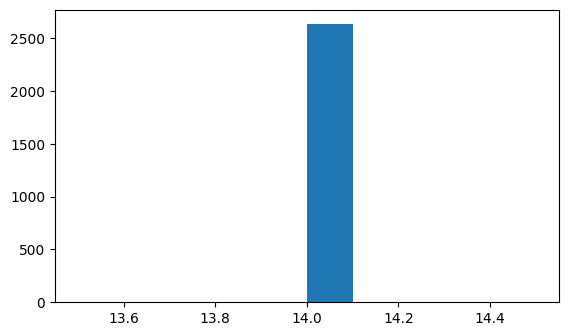

Минимум / медиана / максимум степеней: 14 14.0 14


In [ ]:
degree = np.asarray((D > 0).sum(axis=1)).ravel()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(degree, bins=10)
plt.show()

print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

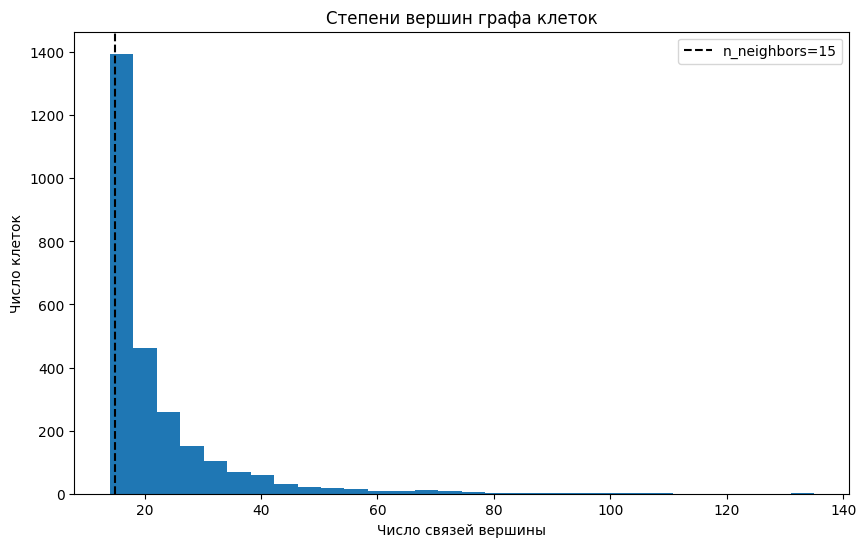

Число компонент связности: 1
Минимум / медиана / максимум степеней: 14 18.0 135


In [ ]:
from scipy.sparse.csgraph import connected_components

degree = np.asarray((G > 0).sum(axis=1)).ravel()
components, labels_components = connected_components(G, directed=False)
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(degree, bins=30)
ax.axvline(15, ls="--", color="black", label="n_neighbors=15")
ax.set(xlabel="Число связей вершины", ylabel="Число клеток",
       title="Степени вершин графа клеток")
ax.legend()
plt.show()
print("Число компонент связности:", components)
print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

# 3. Графовая кластеризация: Louvain → Leiden

**Кластеризация** — разбиение объектов на группы. Но «хорошая группа» должна иметь математическое определение.

- В методах типа k-means группа — набор точек, близких к общему центроиду.
- В графовых методах **сообщество** — группа вершин, которые связаны друг с другом сильнее, чем ожидалось бы при случайном соединении вершин по подходящей нулевой модели.

## 3.1. Модулярность: что оптимизирует алгоритм

Рассмотрим **ненаправленный граф** с матрицей весов $A=(A_{ij})$. Обозначим:

- $A_{ij}$ — вес ребра между вершинами $i$ и $j$;
- $k_i=\sum_j A_{ij}$ — взвешенная степень вершины $i$;
- $2m=\sum_i k_i$ — сумма весов рёбер, посчитанных по двум концам;
- $c_i$ — номер сообщества вершины $i$;
- $\mathbf{1}(c_i=c_j)$ равен единице, когда вершины в одной группе.

Одна из функций качества разбиения — **модулярность с параметром разрешения $\gamma$**:

$$
Q_{\gamma}=\frac{1}{2m}\sum_{i,j}
\left(A_{ij}-\gamma\frac{k_i k_j}{2m}\right)
\mathbf{1}(c_i=c_j).
$$

**Как понимать формулу:**

- $A_{ij}$ — наблюдаемый вес связи;
- $k_i k_j/(2m)$ — ожидаемый вес связи в модели случайного графа, сохраняющей ожидаемые степени вершин;
- в сумму попадают только пары вершин **из одной группы**;
- алгоритм пытается найти разбиение с **высоким значением $Q_\gamma$**.

$\gamma$ отвечает за масштаб: при большем $\gamma$ крупные сообщества сильнее «штрафуются», поэтому на практике часто появляются более мелкие кластеры. **Но число кластеров не обязано расти строго монотонно** из-за устройства графа и эвристической оптимизации.

## 3.2. Louvain и Leiden: чем они отличаются

**Louvain (2008):**

1. Стартует с отдельных сообществ (каждая вершина сама по себе).
2. По очереди переносит вершины между соседними сообществами, если растёт функция качества.
3. Объединяет сообщества в новые супервершины и повторяет оптимизацию.

**Проблема:** в отдельных случаях найденное сообщество может иметь плохую внутреннюю связность или даже быть несвязным.

**Leiden (2019)** добавляет **этап уточнения (refinement)** сообщества до агрегации. В результате алгоритм устраняет известную проблему несвязных сообществ Louvain и при сходимости предоставляет более сильные гарантии внутренней связности. Это **не означает**, что любой кластер Leiden биологически однороден.


Статья: [Traag, Waltman & van Eck, 2019 — From Louvain to Leiden](https://doi.org/10.1038/s41598-019-41695-z).

## 3.3. Leiden на PBMC 3k

Запустим Leiden несколько раз на **одном и том же графе**. Вызовы не используют координаты UMAP.

/tmp/ipykernel_779/1703150331.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")


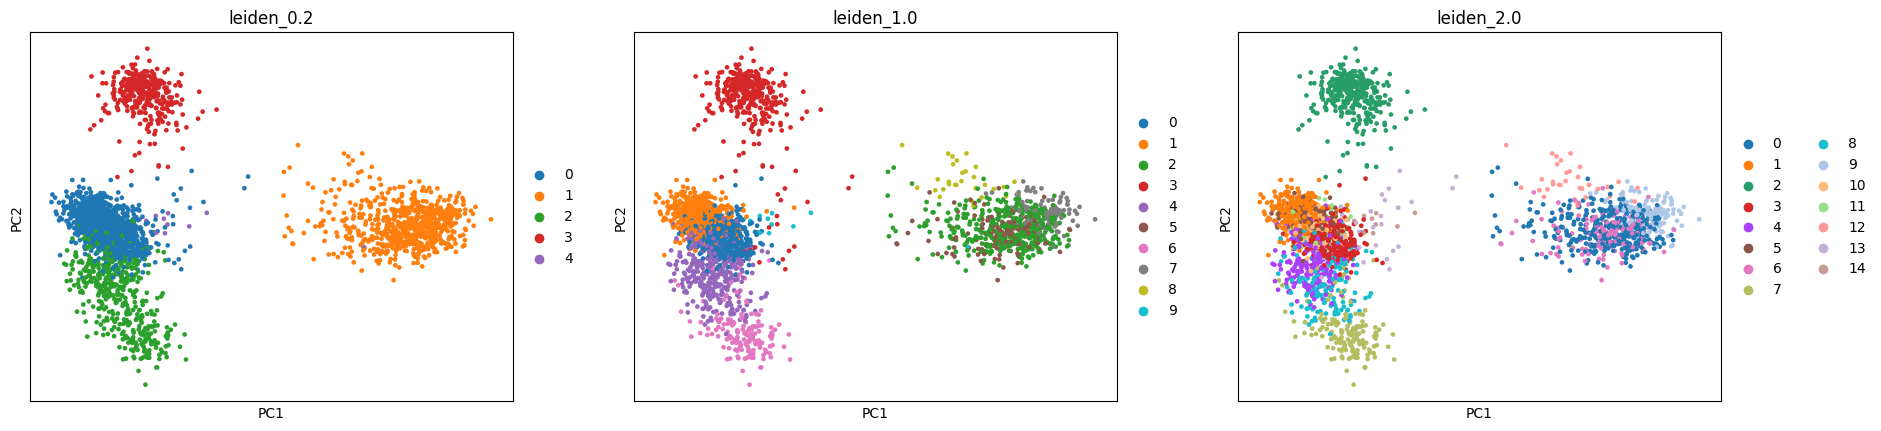

leiden_1.0
0    548
1    541
2    378
3    360
4    349
5    157
6    156
7    107
8     30
9     12
Name: count, dtype: int64


<Axes: xlabel='leiden_1.0'>

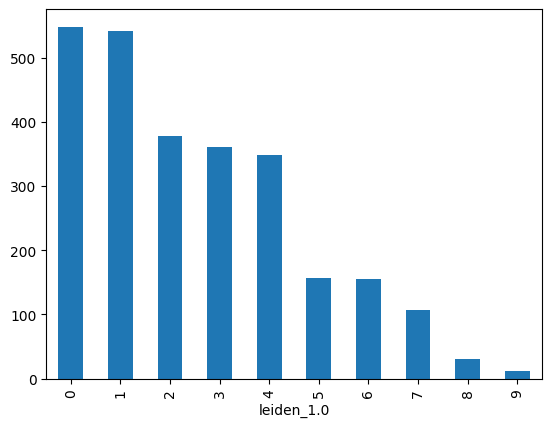

In [ ]:
sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
sc.tl.leiden(adata, resolution=1.0, key_added="leiden_1.0")
sc.tl.leiden(adata, resolution=2.0, key_added="leiden_2.0")

sc.pl.pca(
    adata,
    color=["leiden_0.2", "leiden_1.0", "leiden_2.0"],
    ncols=3
)
# Посмотрим, сколько получилось кластеров
print(adata.obs["leiden_1.0"].value_counts())
adata.obs["leiden_1.0"].value_counts().sort_index().plot.bar()

# 4. Переход из 30 измерений в два: t-SNE и UMAP

## 4.1. t-SNE: сохраняем вероятности соседства

Идея t-SNE: описать, насколько клетка $j$ является соседом клетки $i$, **вероятностью**, а затем подобрать на плоскости такую картинку, чтобы отношения соседства были похожими.

В высокоразмерном пространстве PCA условные вероятности определяются расстояниями:

$$
p_{j\mid i}=\frac{\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_j\|^2}{2\sigma_i^2}\right)}
{\sum_{k\ne i}\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_k\|^2}{2\sigma_i^2}\right)},\quad p_{i\mid i}=0.
$$

Далее строятся симметричные $p_{ij}=(p_{j\mid i}+p_{i\mid j})/(2n)$.

На двумерной карте используются тяжёлые хвосты распределения Стьюдента:

$$
q_{ij}=\frac{(1+\|\mathbf y_i-\mathbf y_j\|^2)^{-1}}
{\sum_{k\ne \ell}(1+\|\mathbf y_k-\mathbf y_\ell\|^2)^{-1}}.
$$

Подбираем координаты $\mathbf y_i$, минимизируя **KL-дивергенцию**:

$$
D_{\mathrm{KL}}(P\|Q)=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.
$$

**Смысл:** большие $p_{ij}$ «требуют», чтобы на карте $q_{ij}$ тоже были большими. Тяжёлые хвосты помогают разнести точки, которые не являются соседями.

`perplexity` управляет эффективным масштабом локального соседства: $\operatorname{Perp}(P_i)=2^{H(P_i)}$, где энтропия считается с логарифмом по основанию 2. Это **не точное число соседей** и не число кластеров.

## 4.2. UMAP: сохраняем взвешенное локальное соседство

UMAP начинает с соседей, строит **взвешенный граф** локального соседства и ищет координаты $\mathbf y_i$ на плоскости, при которых локальные связи остаются похожими.

В упрощённой записи направленные веса близости оцениваются как

$$
w_{j\mid i}=\exp\left[-\frac{\max\{0,d(i,j)-\rho_i\}}{\sigma_i}\right],
$$

где $\rho_i$ — локальное расстояние до ближайшего ненулевого соседа, $\sigma_i$ — локальный масштаб. Вес может затем объединяться с обратным $w_{i\mid j}$ по правилу

$$
w_{ij}=w_{j\mid i}+w_{i\mid j}-w_{j\mid i}w_{i\mid j}.
$$

На плоскости близость приближается функцией вида

$$
\hat w_{ij}=\frac{1}{1+a\|\mathbf y_i-\mathbf y_j\|^{2b}},
$$

где $a,b$ зависят от настроек формы кривой. **Идея функции потерь** — кросс-энтропия между весами связей исходного графа и весами на плоскости:

$$
\mathcal L=-\sum_{i<j}\left[
 w_{ij}\log\hat w_{ij}+(1-w_{ij})\log(1-\hat w_{ij})\right].
$$

Реальная оптимизация использует приближения, включая отрицательное семплирование несоседних пар. Формула выше описывает **математическую цель**, а не буквальный полный перебор всех пар в каждой итерации.

Параметры:

- **`n_neighbors`** (в `sc.pp.neighbors`) определяет масштаб исходных локальных отношений.
- **`min_dist`** (в `sc.tl.umap`) регулирует, насколько плотно точки могут располагаться на карте.
- **`random_state`** задаёт воспроизводимый случайный старт/другие случайные шаги алгоритма.

## Полезно посмотреть
* https://github.com/NikolayOskolkov/HowUMAPWorks/blob/master/HowUMAPWorks.ipynb   
* https://pair-code.github.io/understanding-umap/

# 5.Leiden + UMAP + t-SNE

**Цель:** выполнить обе визуализации для **одних и тех же клеток и одних и тех же меток Leiden**. Только так можно корректно сравнивать полученные картинки.

`sc.tl.umap()` использует уже построенный граф соседства. `sc.tl.tsne()` ниже явно использует первые 30 PC.

In [ ]:
sc.tl.umap(adata, min_dist=0.3, random_state=42)

sc.tl.tsne(adata, use_rep="X_pca", n_pcs=30, perplexity=30, random_state=42)

In [ ]:
print("UMAP:", adata.obsm["X_umap"].shape,
      "t-SNE:", adata.obsm["X_tsne"].shape)

UMAP: (2638, 2) t-SNE: (2638, 2)


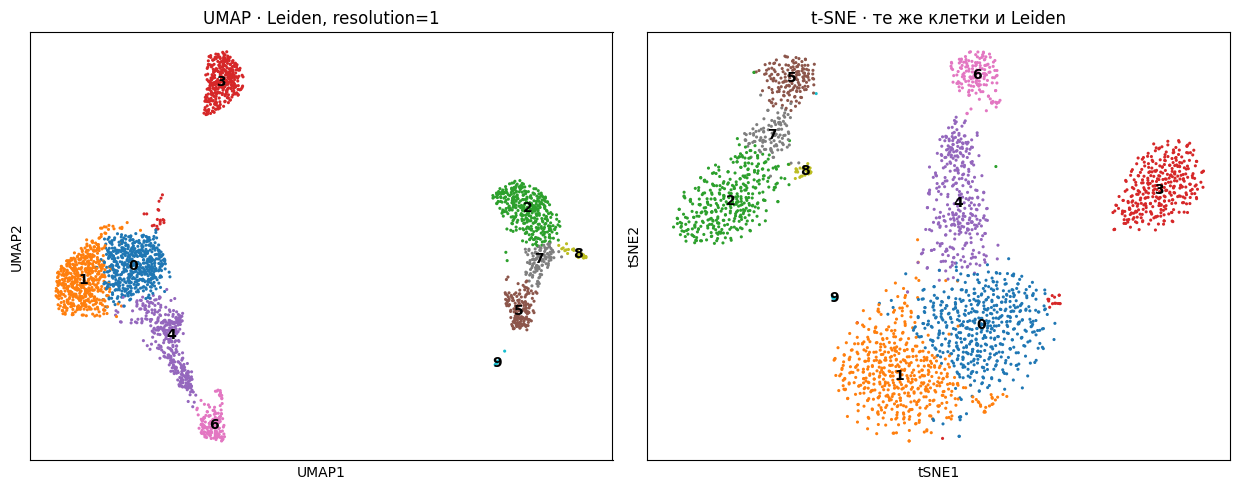

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0))
sc.pl.umap(adata, color="leiden_1.0", legend_loc="on data",
           title="UMAP · Leiden, resolution=1", ax=axes[0], show=False, size=20)
sc.pl.tsne(adata, color="leiden_1.0", legend_loc="on data",
           title="t-SNE · те же клетки и Leiden", ax=axes[1], show=False, size=20)
plt.tight_layout()
plt.show()

## 5.1. Проверяем, что картинка не равна кластеризации

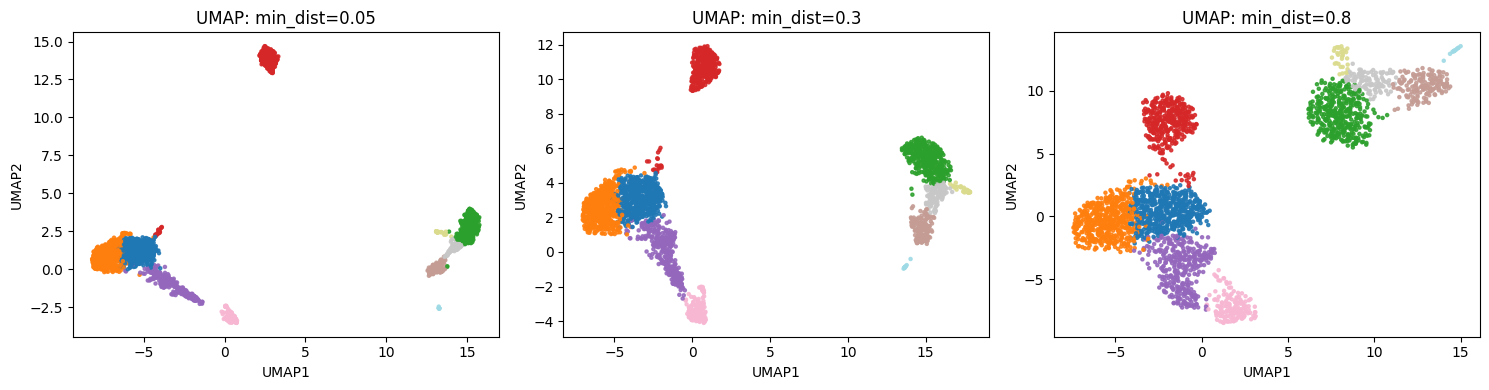

In [ ]:
from copy import deepcopy
original_umap_params = deepcopy(adata.uns.get("umap", {}))
original_embedding = adata.obsm["X_umap"].copy()
original_labels = adata.obs["leiden_1.0"].copy()

embeddings = {0.3: original_embedding}
for value in (0.05, 0.8):
    sc.tl.umap(adata, min_dist=value, random_state=42)
    embeddings[value] = adata.obsm["X_umap"].copy()

adata.obsm["X_umap"] = original_embedding  # возвращаем основной UMAP
adata.uns["umap"] = original_umap_params  # и исходные параметры в AnnData
assert original_labels.equals(adata.obs["leiden_1.0"])

labels = adata.obs["leiden_1.0"].cat.codes.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (value, xy) in zip(axes, sorted(embeddings.items())):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab20", s=5, alpha=0.85)
    ax.set(title=f"UMAP: min_dist={value}", xlabel="UMAP1", ylabel="UMAP2")
plt.tight_layout()
plt.show()

## 5.2. Проверка через биологию

Окрасим UMAP по известным генам-маркерам: `CD3D` (T-клетки), `MS4A1` (B-клетки), `NKG7` (NK-клетки), `LST1` (моноциты).

In [ ]:
markers = [g for g in ["CD3D", "MS4A1", "NKG7", "LST1"] if g in adata.var_names]

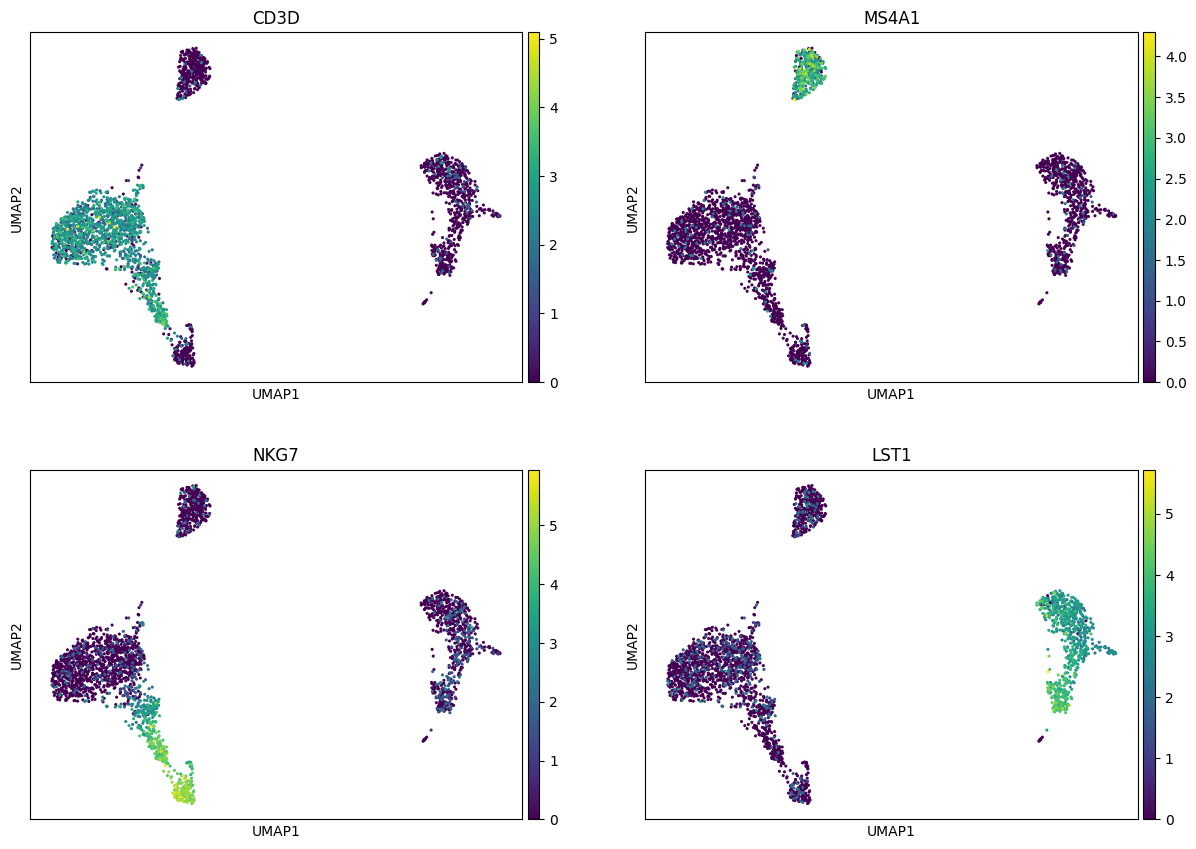

In [ ]:
sc.pl.umap(adata, color=markers, ncols=2, size=20)

## 5.3. Сохраняем результаты для следующего занятия

В `.h5ad` сохраняются исходная матрица, `X_pca`, граф соседства, все варианты меток Leiden и основная визуализация `X_umap`/`X_tsne`. На следующем семинаре можно начать с аннотации кластеров, не повторяя вычисления.

In [ ]:
result_path = Path("data/pbmc3k_after_clustering.h5ad")
adata.write_h5ad(result_path, compression="gzip")

#Домашка_3

###Бганцова Полина Б06-304в

# Самостоятельная работа: модулярность и анализ scRNA-seq

## Задание 1. Посчитать модулярность вручную

На рисунке показан **неориентированный невзвешенный граф из 9 вершин**. Рёбра внутри сообщества проведены сплошными линиями, между сообществами — пунктирными.

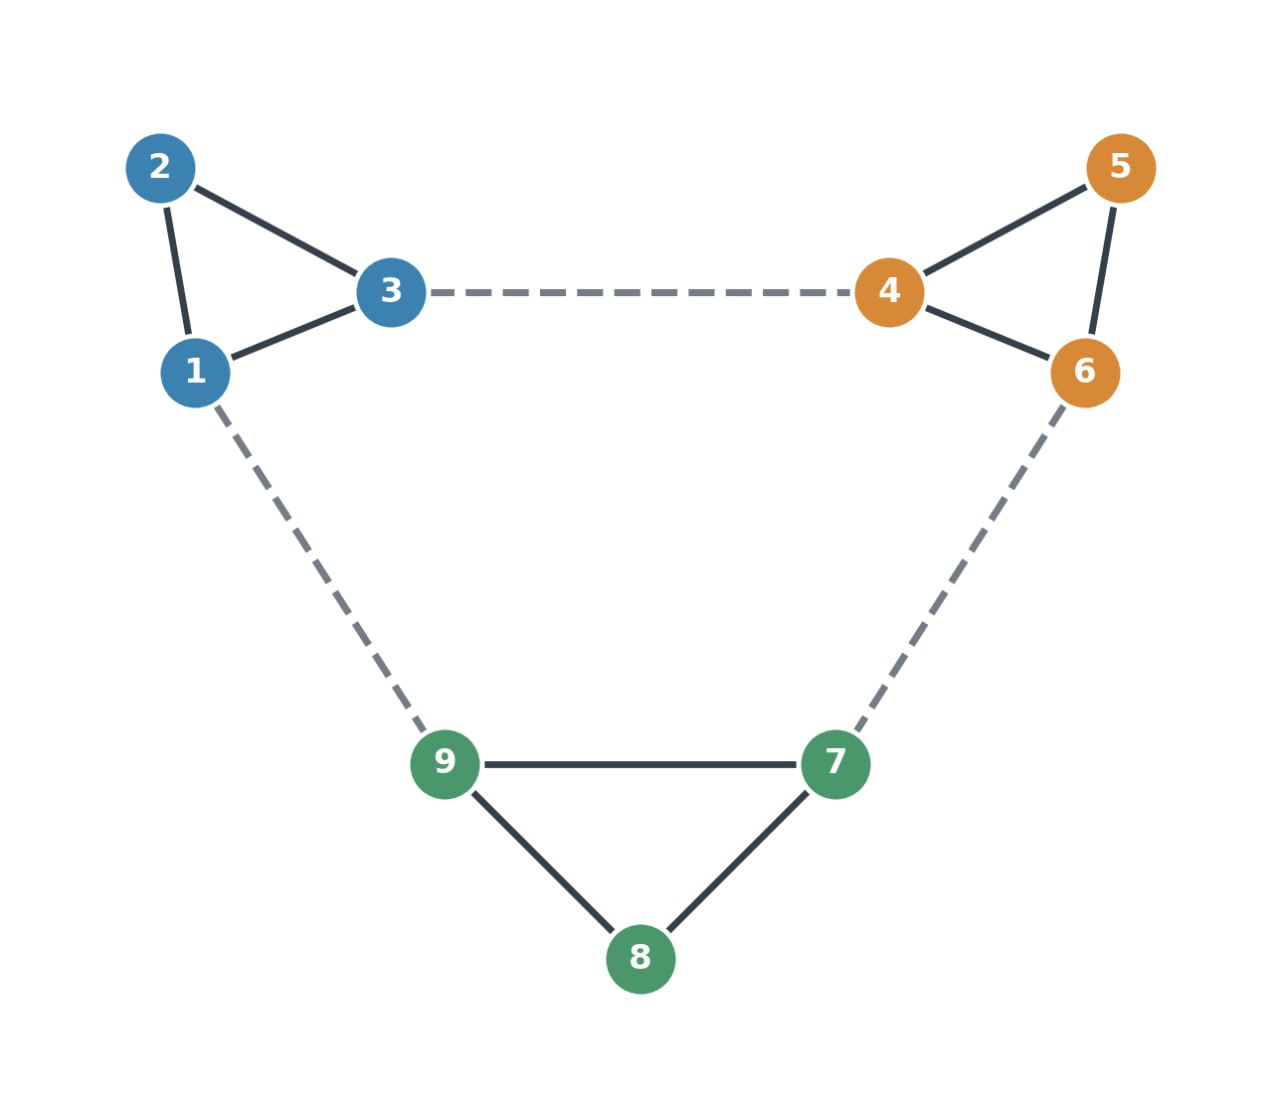



Сообщества: **A = {1, 2, 3}**, **B = {4, 5, 6}**, **C = {7, 8, 9}**.

1. Посчитайте общее число рёбер графа `m`.
2. Для каждого сообщества найдите `l_c` — число рёбер, оба конца которых находятся внутри сообщества, и `d_c` — сумму степеней его вершин (включая внешние связи).
3. По формуле ниже вычислите **модулярность разбиения вручную**, показав промежуточные вычисления:

   $$Q=\sum_{c=1}^{3}\left(\frac{l_c}{m}-\left(\frac{d_c}{2m}\right)^2\right).$$

4. Объясните словами, зачем из доли внутренних рёбер вычитается второй член. Что показывает положительное значение `Q`? Является ли `Q` вероятностью?

### Задание 1. Расчёт модулярности графа

**1. Общее количество рёбер**

В графе 9 внутренних рёбер (по 3 в каждом сообществе) и 3 внешних.

$$
m=9+3=12
$$

**2. Внутренние рёбра и суммы степеней**

| Сообщество | Внутренние рёбра \(l_c\) | Сумма степеней \(d_c\) |
|---|---|---|
| A = {1, 2, 3} | 3 | 8 |
| B = {4, 5, 6} | 3 | 8 |
| C = {7, 8, 9} | 3 | 8 |

Сумма степеней каждого сообщества равна 8, поскольку три внутренних ребра дают 6, а два внешних — ещё 2.

**3. Расчёт модулярности**

$$
Q=\sum_{c=1}^{3}\left[\frac{l_c}{m}-\left(\frac{d_c}{2m}\right)^2\right]
$$

Для каждого сообщества:

$$
Q_c=\frac{3}{12}-\left(\frac{8}{24}\right)^2
=\frac14-\frac19=\frac5{36}
$$

Общая модулярность:

$$
Q=3\cdot\frac5{36}=\frac5{12}\approx0{,}417
$$

**4. Объяснение результата**

Второй член формулы вычитается, чтобы учесть ожидаемую долю внутренних связей в случайном графе с сохранением степеней вершин. Таким образом, модулярность оценивает, насколько реальное количество внутренних рёбер превышает случайно ожидаемое.

Положительное значение \(Q\approx0{,}417\) означает, что внутри сообществ связей больше, чем ожидалось бы случайно. Следовательно, граф имеет выраженную структуру сообществ.

**Модулярность не является вероятностью.** Это показатель качества разбиения графа на сообщества, который может принимать в том числе отрицательные значения.


## Задание 2. Самостоятельный анализ клеток в Scanpy

**Выберите один** набор 10x Genomics (PBMC 3k не использовать):

- [Клетки сердца эмбриона мыши E18 (~1011 клеток)](https://www.10xgenomics.com/datasets/1-k-heart-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки головного мозга эмбриона мыши E18 (~1301 клетка)](https://www.10xgenomics.com/datasets/1-k-brain-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки селезёнки мыши (~1119 клеток)](https://www.10xgenomics.com/datasets/splenocytes-from-c-57-bl-6-mice-1-k-cells-v-2-2-standard-4-0-0)

На странице набора загрузите **Feature / cell matrix HDF5 (filtered)** (для селезёнки — матрицу **Gene Expression**, а не V(D)J). Это счётчики UMI для баркодов, уже отобранных Cell Ranger; исходные пустые капли в эту матрицу не входят.

```python
import scanpy as sc
adata = sc.read_10x_h5("путь/к/скачанному_файлу.h5")
adata.var_names_make_unique()
```

**Проведите анализ**, используя методы Scanpy, изученные на семинарах:

1. **QC.** Посчитайте и покажите распределения количества UMI (`total_counts`), обнаруженных генов (`n_genes_by_counts`) и доли митохондриальных счётчиков (`pct_counts_mt`). Выберите пороги фильтрации клеток и генов, примените их и **объясните почему выбрали именно эти значения**. Укажите, сколько клеток осталось.
2. **Нормализация и HVG.** Выполните нормализацию, `log1p` и отбор высоковариабельных генов. Укажите число HVG и объясните, зачем их отбирают и почему выбранное количество разумно.
3. **PCA.** Постройте PCA. Выберите число главных компонент для дальнейшего анализа; объясните выбор, используя график доли объяснённой дисперсии.
4. **Граф и Leiden.** Постройте граф соседей, выполните кластеризацию Leiden. Укажите `n_neighbors`, `n_pcs`, `resolution`, число получившихся кластеров и число клеток в них. Объясните выбранные параметры.
5. **UMAP и t-SNE.** Постройте обе визуализации, раскрасив точки по меткам Leiden. Также раскрасьте PCA или UMAP по одной QC-метрике и по **двум выбранным известным генам**, если они есть в данных. Опишите, что видно и какие выводы сделать нельзя.
6. **Биологический вывод.** По нескольким предложениям объясните, какие клеточные популяции **предположительно** присутствуют в выбранной ткани. Обоснуйте предположение экспрессией выбранных генов; не называйте кластеры достоверно определёнными клеточными типами.

**Разрешено:** стандартные функции Scanpy для QC, фильтрации, нормализации, HVG, PCA, графа соседей, Leiden, UMAP и t-SNE; окраска графиков по кластерам, QC-метрикам и **заданным вручную** генам.

**Не использовать:** `sc.tl.rank_genes_groups`, `sc.tl.score_genes`, методы автоматической аннотации или другие ещё не изученные методы. Подбор генов можно сделать по литературе, без автоматического поиска маркеров.

**Что сдавать:** число и расчёт модулярности; Jupyter-ноутбук с анализом одного набора данных, графиками, числом клеток до/после QC, параметрами и краткими объяснениями сделанных решений. Не требуется получить «правильное» число кластеров.


In [28]:
adata_spleen = sc.read_10x_h5(
    "/content/sc5p_v2_mm_c57bl6_splenocyte_1k_filtered_feature_bc_matrix.h5"
)

adata_spleen.var_names_make_unique()

print(adata_spleen)

AnnData object with n_obs × n_vars = 1119 × 32285
    var: 'gene_ids', 'feature_types', 'genome'


/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [29]:
# Отмечаем митохондриальные гены мыши
adata_spleen.var["mt"] = adata_spleen.var_names.str.startswith("mt-")

# Проверяем количество
print("Митохондриальных генов:",
      adata_spleen.var["mt"].sum())

print(adata_spleen.var_names[adata_spleen.var["mt"]])

Митохондриальных генов: 13
Index(['mt-Nd1', 'mt-Nd2', 'mt-Co1', 'mt-Co2', 'mt-Atp8', 'mt-Atp6', 'mt-Co3',
       'mt-Nd3', 'mt-Nd4l', 'mt-Nd4', 'mt-Nd5', 'mt-Nd6', 'mt-Cytb'],
      dtype='object')


In [30]:
sc.pp.calculate_qc_metrics(
    adata_spleen,
    qc_vars=["mt"],
    percent_top=None,
    inplace=True
)

adata_spleen.obs[
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
].head()

,n_genes_by_counts,total_counts,pct_counts_mt
AAACCTGCATTCTTAC-1,2776,10015.0,3.245132
AAACGGGAGGGTCTCC-1,1324,3224.0,5.521092
AAACGGGTCAACACTG-1,2414,6356.0,1.683449
AAACGGGTCGCCCTTA-1,1111,2566.0,3.624318
AAAGATGAGAACTCGG-1,2265,6672.0,2.757794


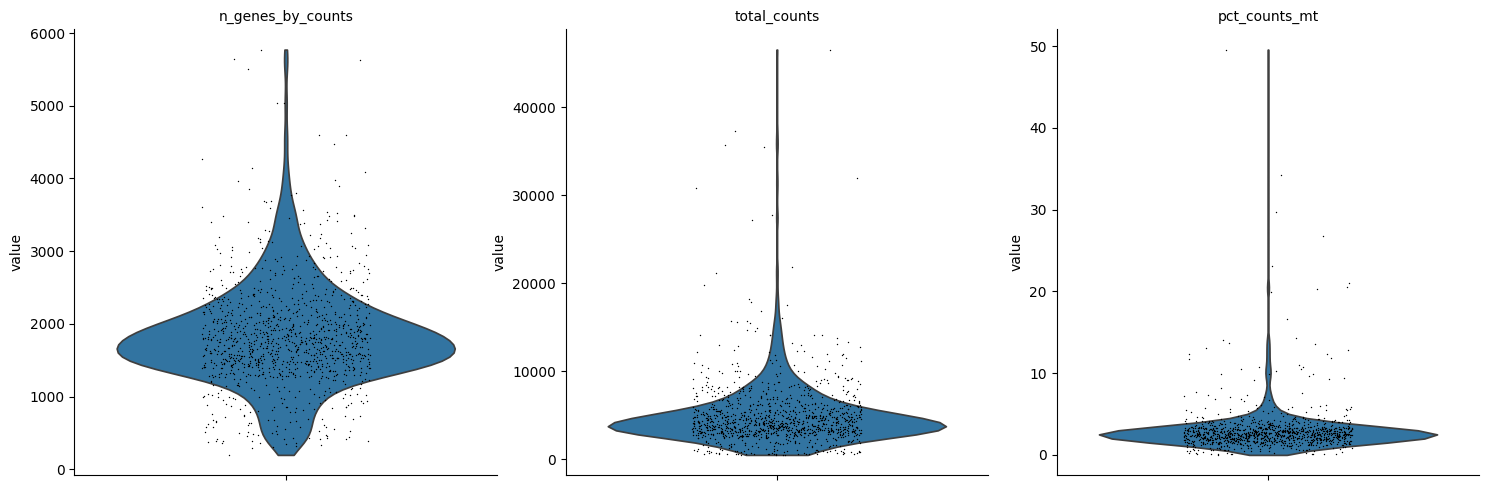

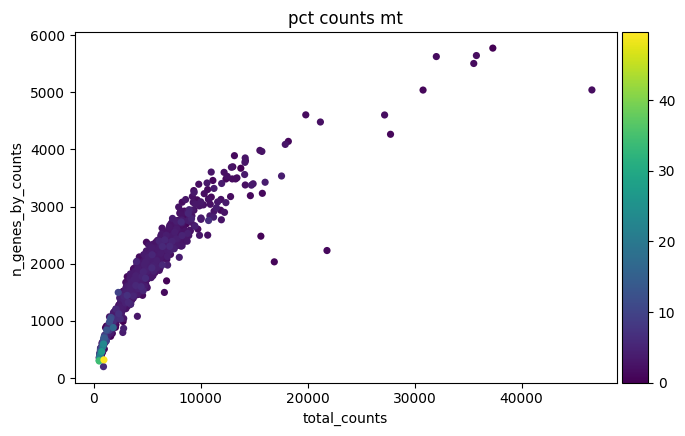

In [31]:
import matplotlib.pyplot as plt

# Violin plots
sc.pl.violin(
    adata_spleen,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    multi_panel=True,
    jitter=0.2
)

# Scatter plot
sc.pl.scatter(
    adata_spleen,
    x="total_counts",
    y="n_genes_by_counts",
    color="pct_counts_mt"
)

In [32]:
# Сохраняем количество клеток до фильтрации
n_before = adata_spleen.n_obs

# Фильтруем клетки по QC-показателям
adata_spleen = adata_spleen[
    (adata_spleen.obs["n_genes_by_counts"] >= 500) &
    (adata_spleen.obs["n_genes_by_counts"] <= 4000) &
    (adata_spleen.obs["pct_counts_mt"] < 10)
].copy()

# Удаляем гены, обнаруженные менее чем в 3 клетках
sc.pp.filter_genes(adata_spleen, min_cells=3)

print("Клеток до QC:", n_before)
print("Клеток после QC:", adata_spleen.n_obs)
print("Удалено клеток:", n_before - adata_spleen.n_obs)
print("Генов после QC:", adata_spleen.n_vars)

Клеток до QC: 1119
Клеток после QC: 1063
Удалено клеток: 56
Генов после QC: 12855


### Выбор порогов QC

По распределениям QC-метрик выбраны пороги 500–4000 обнаруженных генов на клетку и менее 10% митохондриальных UMI. Они позволяют исключить клетки с очень низкой сложностью экспрессии, высокой долей митохондриальных транскриптов и потенциальные дублеты.

Гены, обнаруженные менее чем в трёх клетках, удалены как крайне редко встречающиеся. После QC сохранилось 1063 из 1119 клеток (95%).

Клеток: 1063
Генов: 12855
HVG: 2000


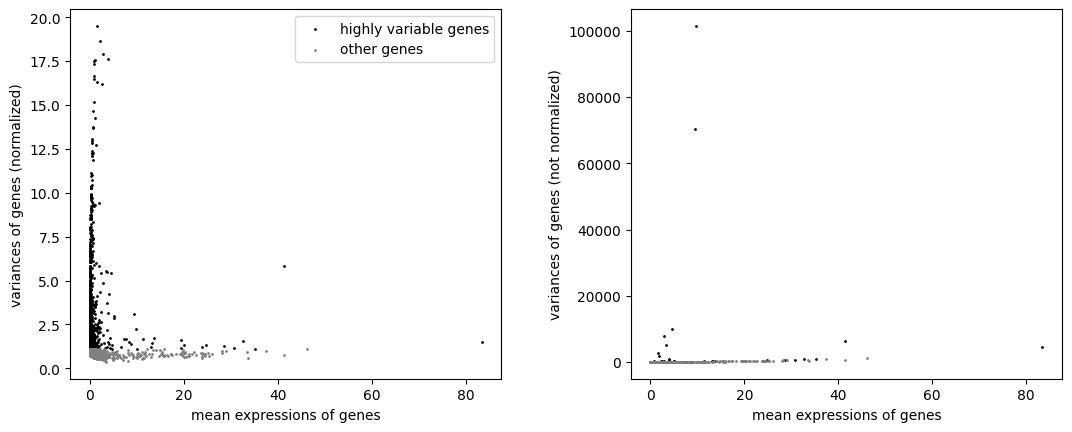

In [33]:
# Сохраняем исходные UMI counts после QC
adata_spleen.layers["counts"] = adata_spleen.X.copy()

# Выбираем 2000 HVG по исходным counts
sc.pp.highly_variable_genes(
    adata_spleen,
    layer="counts",
    flavor="seurat_v3",
    n_top_genes=2000
)

# Нормализация
sc.pp.normalize_total(adata_spleen, target_sum=1e4)

# Логарифмирование
sc.pp.log1p(adata_spleen)

print("Клеток:", adata_spleen.n_obs)
print("Генов:", adata_spleen.n_vars)
print("HVG:", adata_spleen.var["highly_variable"].sum())

# Визуализация HVG
sc.pl.highly_variable_genes(adata_spleen)

### Выбор HVG

Для анализа выбраны 2000 высоковариабельных генов методом `seurat_v3`. HVG позволяют сосредоточиться на генах, отражающих различия между клетками, и уменьшить влияние малоинформативных признаков.

Количество 2000 выбрано как распространённый компромисс между сохранением биологической информации и уменьшением размерности данных.

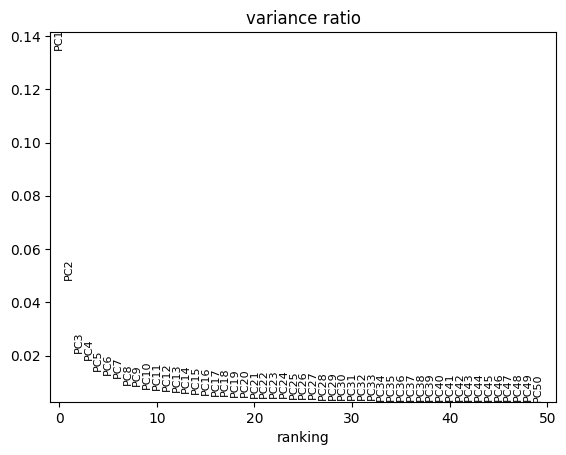

Размер PCA: (1063, 50)


In [34]:
sc.tl.pca(
    adata_spleen,
    n_comps=50,
    mask_var="highly_variable",
    random_state=42
)

sc.pl.pca_variance_ratio(
    adata_spleen,
    n_pcs=50,
    log=False
)

print("Размер PCA:", adata_spleen.obsm["X_pca"].shape)

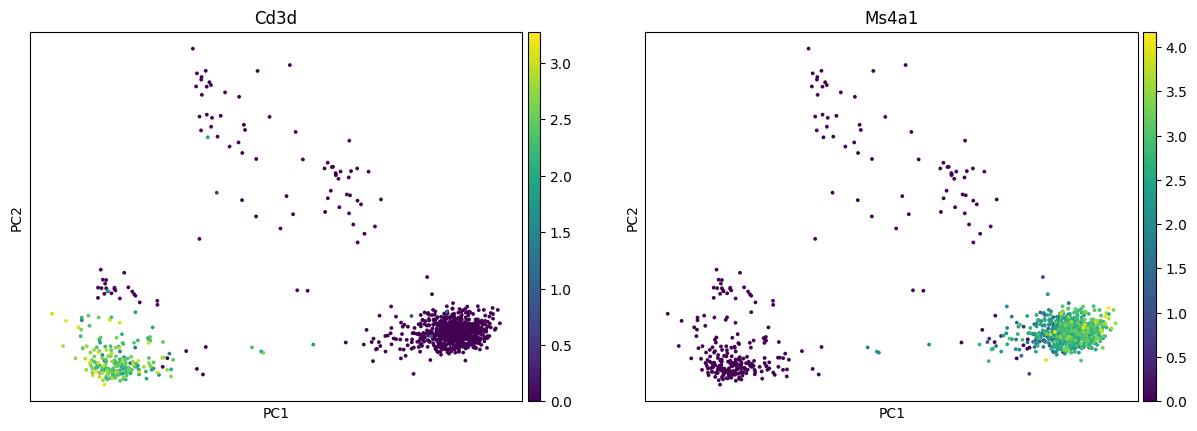

In [44]:
sc.pl.pca(
    adata_spleen,
    color=["Cd3d", "Ms4a1"],
    ncols=2,
    size=30
)

### Выбор числа главных компонент

PCA рассчитан по 2000 HVG. Первая компонента объясняет около 14% дисперсии, вторая — около 5%. После 10–15 компонент вклад последующих постепенно стабилизируется.

Для построения графа соседства выбраны первые **15 главных компонент**, поскольку они отражают основную вариацию данных. Выбор предварительный и основан на графике объяснённой дисперсии.

In [35]:
sc.pp.neighbors(
    adata_spleen,
    n_neighbors=15,
    n_pcs=15,
    metric="euclidean",
    random_state=42
)

print("Граф соседства построен!")
print("Размер матрицы связей:",
      adata_spleen.obsp["connectivities"].shape)

Граф соседства построен!
Размер матрицы связей: (1063, 1063)


In [36]:
for resolution in [0.2, 0.5, 1.0]:
    sc.tl.leiden(
        adata_spleen,
        resolution=resolution,
        key_added=f"leiden_{resolution}",
        random_state=42,
        flavor="leidenalg"
    )

    print(f"\nResolution = {resolution}")
    print("Количество кластеров:",
          adata_spleen.obs[f"leiden_{resolution}"].nunique())

    print(
        adata_spleen.obs[f"leiden_{resolution}"]
        .value_counts()
        .sort_index()
    )


Resolution = 0.2
Количество кластеров: 4
leiden_0.2
0    768
1    205
2     65
3     25
Name: count, dtype: int64

Resolution = 0.5
Количество кластеров: 6
leiden_0.5
0    449
1    230
2    137
3    112
4     68
5     67
Name: count, dtype: int64

Resolution = 1.0
Количество кластеров: 13
leiden_1.0
0     193
1     131
2     117
3     113
4     104
5     103
6      82
7      81
8      35
9      32
10     27
11     25
12     20
Name: count, dtype: int64


In [37]:
# Рассчитываем UMAP
sc.tl.umap(
    adata_spleen,
    min_dist=0.3,
    random_state=42
)

# Рассчитываем t-SNE
sc.tl.tsne(
    adata_spleen,
    use_rep="X_pca",
    n_pcs=15,
    perplexity=30,
    random_state=42
)

print("UMAP:", adata_spleen.obsm["X_umap"].shape)
print("t-SNE:", adata_spleen.obsm["X_tsne"].shape)

UMAP: (1063, 2)
t-SNE: (1063, 2)


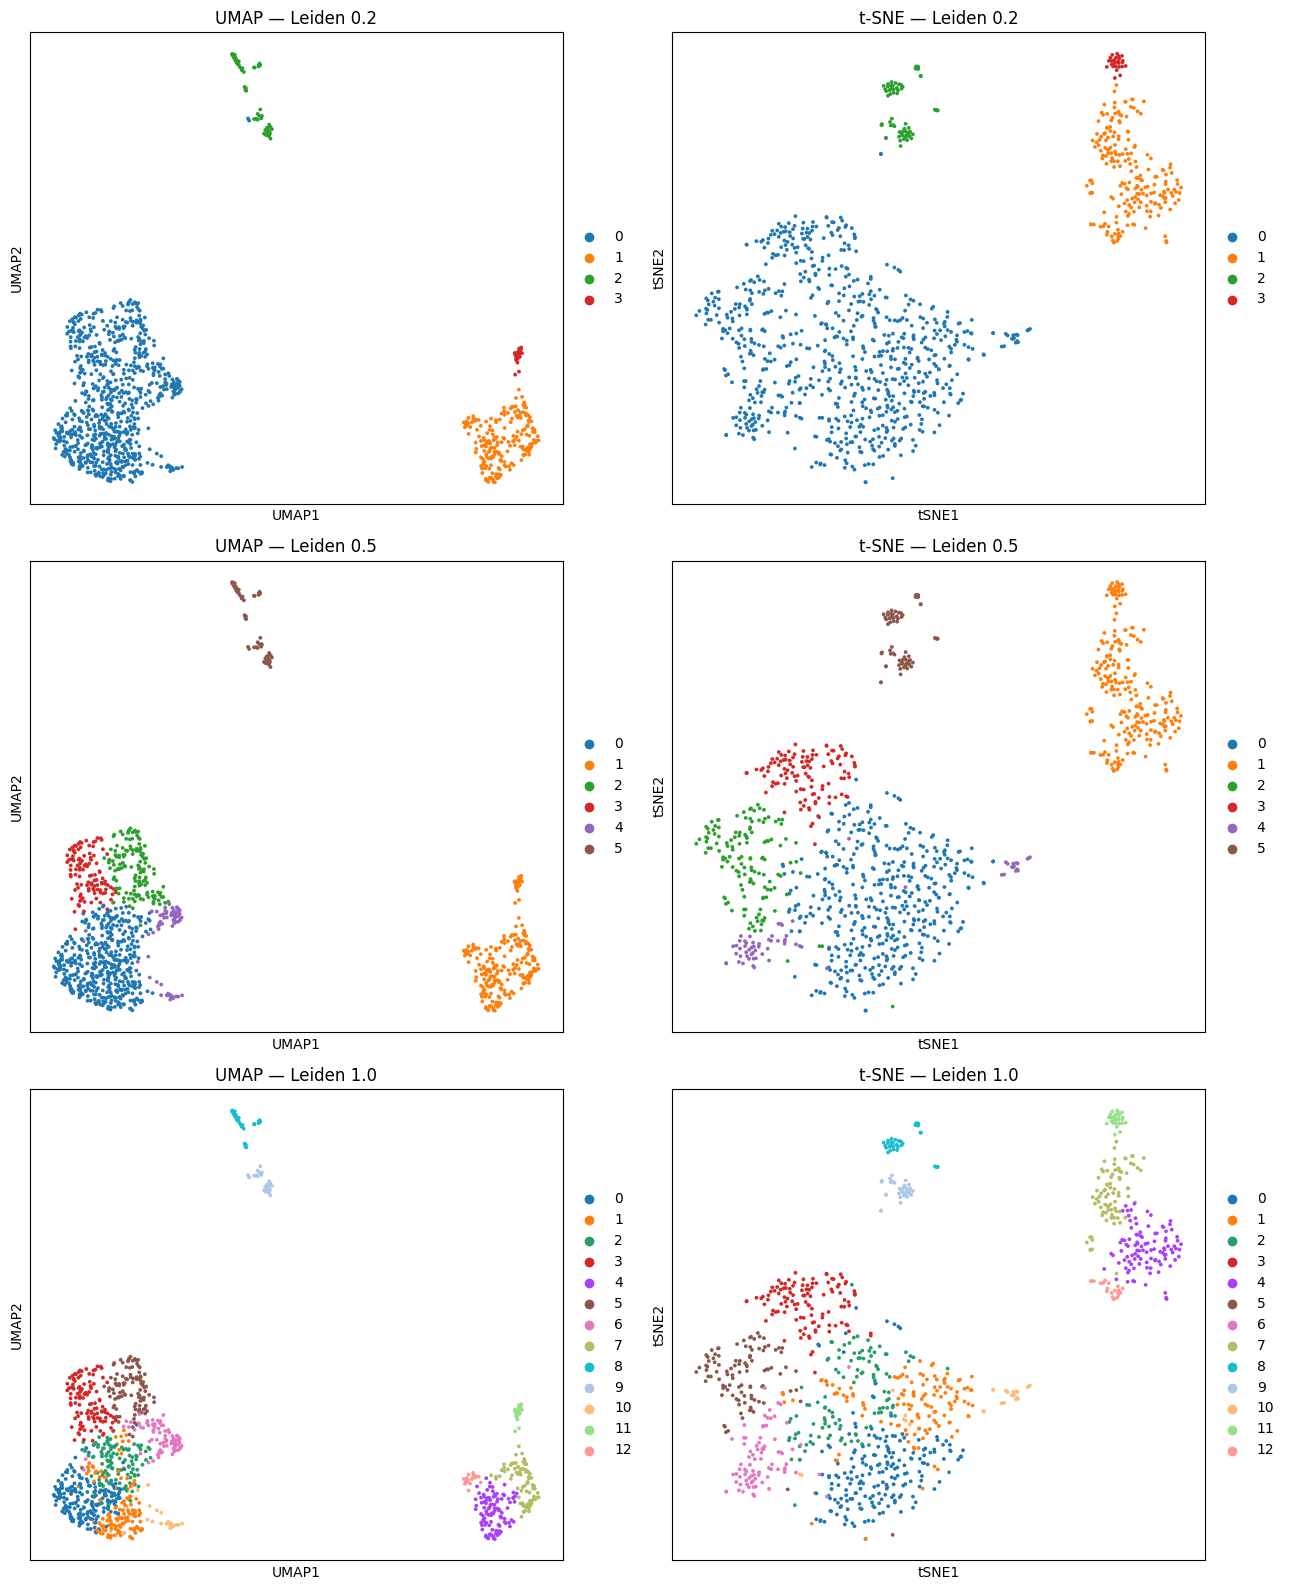

In [38]:
fig, axes = plt.subplots(3, 2, figsize=(13, 16))

for i, resolution in enumerate([0.2, 0.5, 1.0]):
    cluster = f"leiden_{resolution}"

    sc.pl.umap(
        adata_spleen,
        color=cluster,
        ax=axes[i, 0],
        show=False,
        size=30,
        title=f"UMAP — Leiden {resolution}"
    )

    sc.pl.tsne(
        adata_spleen,
        color=cluster,
        ax=axes[i, 1],
        show=False,
        size=30,
        title=f"t-SNE — Leiden {resolution}"
    )

plt.tight_layout()
plt.show()

### Выбор параметров кластеризации

Для построения графа соседства использованы `n_neighbors=15` и `n_pcs=15`. Количество главных компонент выбрано по графику объяснённой дисперсии, а 15 соседей позволяют учитывать локальное сходство клеток.

При `resolution=0.2` получено 4 кластера, при `0.5` — 6, при `1.0` — 13. Выбрано **resolution=0.5**, поскольку оно обеспечивает достаточно подробное разделение клеточных популяций без чрезмерного дробления на мелкие группы.

In [39]:
genes_to_check = ["Cd3d", "Ms4a1", "Nkg7", "Lyz2", "LST1"]

for gene in genes_to_check:
    print(gene, gene in adata_spleen.var_names)

Cd3d True
Ms4a1 True
Nkg7 True
Lyz2 True
LST1 False


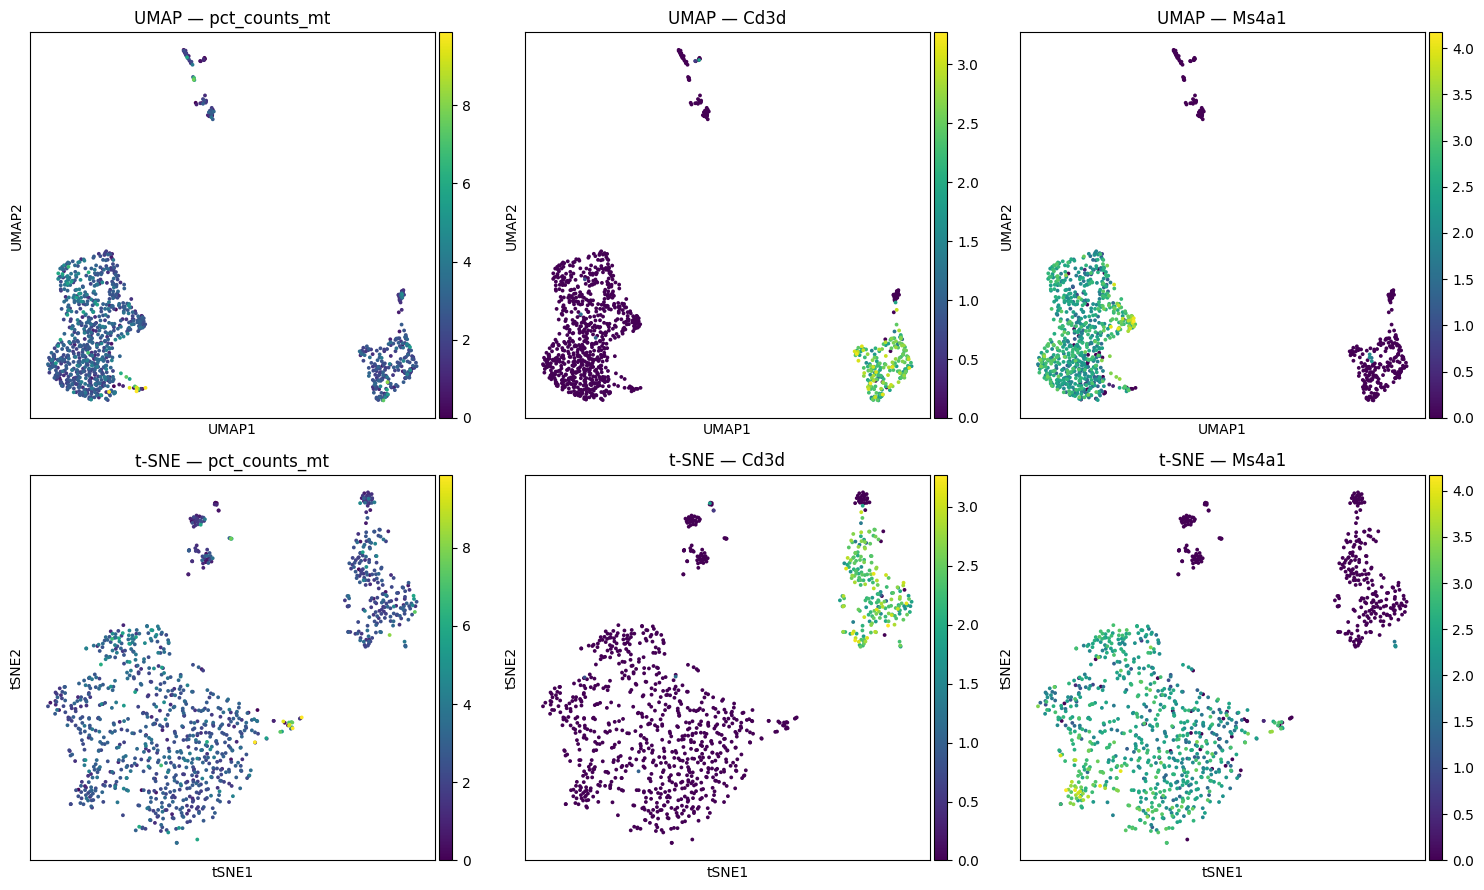

In [40]:
markers = ["pct_counts_mt", "Cd3d", "Ms4a1"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, marker in enumerate(markers):
    sc.pl.umap(
        adata_spleen,
        color=marker,
        ax=axes[0, i],
        show=False,
        size=30,
        title=f"UMAP — {marker}"
    )

    sc.pl.tsne(
        adata_spleen,
        color=marker,
        ax=axes[1, i],
        show=False,
        size=30,
        title=f"t-SNE — {marker}"
    )

plt.tight_layout()
plt.show()

Найдены маркеры: ['Nkg7', 'Lyz2', 'Cd79a', 'S100a8']


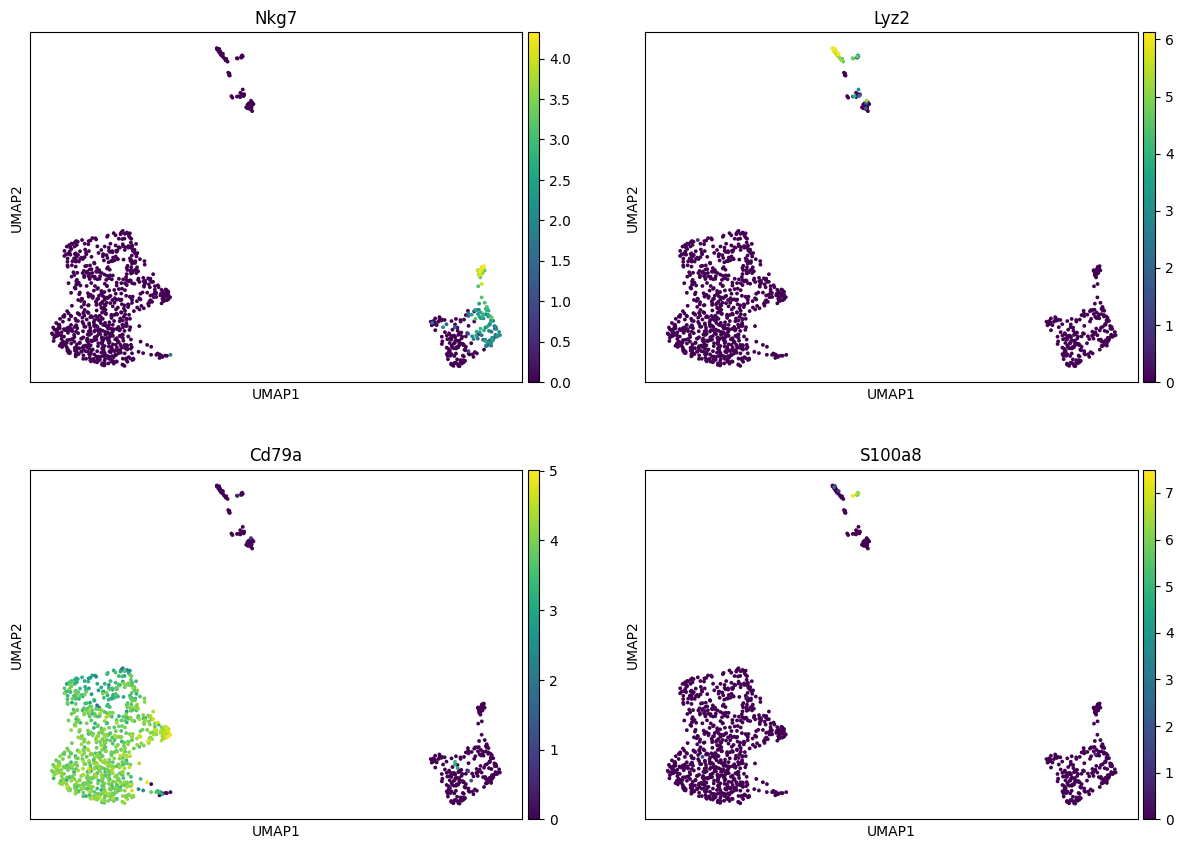

In [41]:
extra_markers = ["Nkg7", "Lyz2", "Cd79a", "S100a8"]

# Проверяем наличие генов
available_markers = [
    gene for gene in extra_markers
    if gene in adata_spleen.var_names
]

print("Найдены маркеры:", available_markers)

# Строим UMAP
sc.pl.umap(
    adata_spleen,
    color=available_markers,
    ncols=2,
    size=30
)

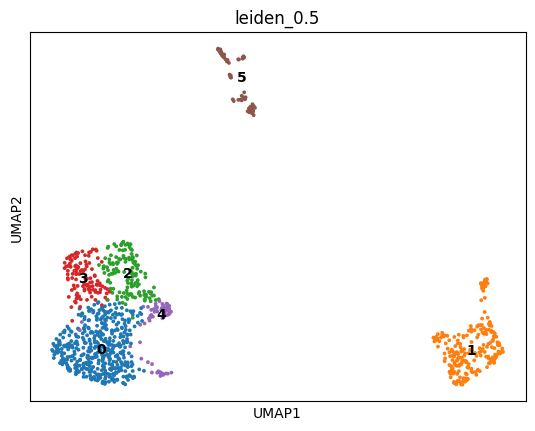

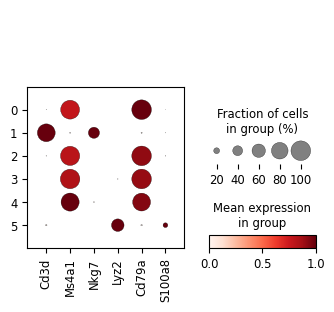

In [42]:
# Кластеры Leiden
sc.pl.umap(
    adata_spleen,
    color="leiden_0.5",
    legend_loc="on data",
    size=30
)

# Средняя экспрессия выбранных маркеров по кластерам
markers = ["Cd3d", "Ms4a1", "Nkg7", "Lyz2", "Cd79a", "S100a8"]

sc.pl.dotplot(
    adata_spleen,
    var_names=markers,
    groupby="leiden_0.5",
    standard_scale="var"
)

### Выводы по заданию 2

Для самостоятельного анализа использован датасет scRNA-seq клеток селезёнки мыши C57BL/6, содержащий 1119 клеток и 32 285 генов.

**1. Контроль качества и предварительная обработка**

После QC-фильтрации осталось 1063 клетки и 12 855 генов. Были выбраны 2000 HVG методом `seurat_v3`, проведены нормализация и логарифмирование. Для построения графа соседства использованы первые 15 главных компонент PCA.

**2. Кластеризация Leiden**

При `resolution=0.2` получено 4 кластера, при `0.5` — 6, при `1.0` — 13. Для дальнейшего анализа выбрано `resolution=0.5`, поскольку оно обеспечивает достаточно подробное разделение без чрезмерного дробления клеточных групп.

**3. Сравнение UMAP и t-SNE**

Оба метода позволяют различить основные клеточные популяции. Хотя расположение и форма кластеров отличаются, принадлежность клеток к группам Leiden сохраняется.

По расстояниям между кластерами на UMAP и t-SNE нельзя напрямую судить об их биологической близости, а по визуальному разделению нельзя достоверно определять клеточные типы. Для этого необходим анализ маркерных генов

**4. Анализ QC и маркерных генов**

После QC доля митохондриальных UMI у всех оставшихся клеток составляет менее 10%. На UMAP и t-SNE не наблюдается отдельной группы, состоящей исключительно из клеток с повышенной митохондриальной экспрессией.

Экспрессия `Cd3d` характерна преимущественно для T-лимфоцитов, тогда как `Ms4a1` и `Cd79a` — для B-лимфоцитов.

**5. Биологическая интерпретация кластеров**

Кластеры 0, 2, 3 и 4 предположительно соответствуют B-лимфоцитам или их подтипам. Кластер 1 представлен преимущественно T-лимфоцитами, среди которых встречаются клетки с экспрессией цитотоксического маркера `Nkg7`. Кластер 5 характеризуется экспрессией `Lyz2` и, вероятно, относится к миелоидным клеткам.

**-->** анализ позволил выделить основные иммунные популяции селезёнки мыши. Кластеризация Leiden, визуализация UMAP и t-SNE и анализ маркерных генов согласуются между собой. Для точного определения клеточных подтипов необходима дополнительная проверка маркеров.

In [43]:
adata_spleen.write_h5ad(
    "data/spleen_after_clustering.h5ad",
    compression="gzip"
)